# 04. Производство: предиктивное обслуживание станков (AI4I 2020)

**Дисциплина:** «Управление и аналитика данных на предприятии» · СПбПУ, ИПМЭиТ · Лекция 7

**Профиль:** Производственный и инновационный менеджмент

**Бизнес-вопрос:** Можно ли по телеметрии станка (температуры, обороты, момент, износ инструмента) заранее выявлять отказы, чтобы перейти от ремонта «по факту» к ремонту «по состоянию»?

**Данные:** `ai4i2020.csv` — 10 000 записей телеметрии фрезерного станка, 3,4% отказов. Источник: [UCI ML Repository, AI4I 2020 Predictive Maintenance Dataset](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset), Matzka, 2020, CC BY 4.0.

---
Ноутбук построен по единому сценарию из 10 шагов (см. лекцию 7): *вопрос → загрузка → паспорт данных → очистка → разведка → связи и тренды → постановка ML-задачи → train/test → модель и базовая линия → качество и вывод для бизнеса*. Запуск: «Среда выполнения → Выполнить всё». Данные загружаются по постоянной ссылке с GitHub — ничего загружать вручную не нужно.

## Шаг 1. Вопрос, гипотеза, цена ошибки

* **Объект** — цикл работы станка; **цель** — `Machine failure` (1 — отказ).
* **Цена ошибки:** пропущенный отказ (FN) = простой линии + брак; ложная тревога (FP) = лишний осмотр. FN дороже → главная метрика **recall**.
* **H1:** отказы связаны с перегревом (малая разница температур), перегрузкой по мощности и износом инструмента.

In [1]:
# Шаг 0. Подключаем библиотеки (как в базовом примере)
import numpy as np                 # вычисления
import pandas as pd                # таблицы
import seaborn as sns              # графики
import matplotlib.pyplot as plt    # графики

sns.set_theme(style="whitegrid", palette=["#37B34A", "#244128", "#7248A0", "#F39768", "#DA4927"])
pd.set_option("display.max_columns", 30)

## Шаги 2–3. Загрузка и паспорт данных

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/alejanro85/uad-lecture7-ml/main/data/ai4i2020.csv")
print(df.shape, "| пропусков:", df.isna().sum().sum())
df.head()

(10000, 14) | пропусков: 0


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.5,2886.9,1.0,2500.8,5000.5,7500.2,10000.0
Air temperature [K],10000.0,300.0,2.0,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,310.0,1.5,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,1538.8,179.3,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,40.0,10.0,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,108.0,63.7,0.0,53.0,108.0,162.0,253.0
Machine failure,10000.0,0.0,0.2,0.0,0.0,0.0,0.0,1.0
TWF,10000.0,0.0,0.1,0.0,0.0,0.0,0.0,1.0
HDF,10000.0,0.0,0.1,0.0,0.0,0.0,0.0,1.0
PWF,10000.0,0.0,0.1,0.0,0.0,0.0,0.0,1.0


In [4]:
print(df["Machine failure"].value_counts())
df[["TWF", "HDF", "PWF", "OSF", "RNF"]].sum().rename({"TWF": "износ инструмента", "HDF": "перегрев", "PWF": "мощность", "OSF": "перегрузка", "RNF": "случайный"})

Machine failure
0    9661
1     339
Name: count, dtype: int64


износ инструмента     46
перегрев             115
мощность              95
перегрузка            98
случайный             19
dtype: int64

**Вывод:** 10 000 записей без пропусков; отказов всего **339 (3,4%)** — сильный дисбаланс. Столбцы TWF…RNF — *типы* уже случившегося отказа: это **утечка ответа**, в признаки их брать нельзя. UDI и Product ID — идентификаторы.

## Шаг 4. Подготовка: убираем идентификаторы и утечку, кодируем категорию

In [5]:
sensors = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
X_raw = pd.get_dummies(df[["Type"] + sensors], columns=["Type"], drop_first=True, dtype=int)   # Type: L/M/H -> 0/1
y = df["Machine failure"]
X_raw.head()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_L,Type_M
0,298.1,308.6,1551,42.8,0,0,1
1,298.2,308.7,1408,46.3,3,1,0
2,298.1,308.5,1498,49.4,5,1,0
3,298.2,308.6,1433,39.5,7,1,0
4,298.2,308.7,1408,40.0,9,1,0


## Шаги 5–6. Разведка: где «живут» отказы?

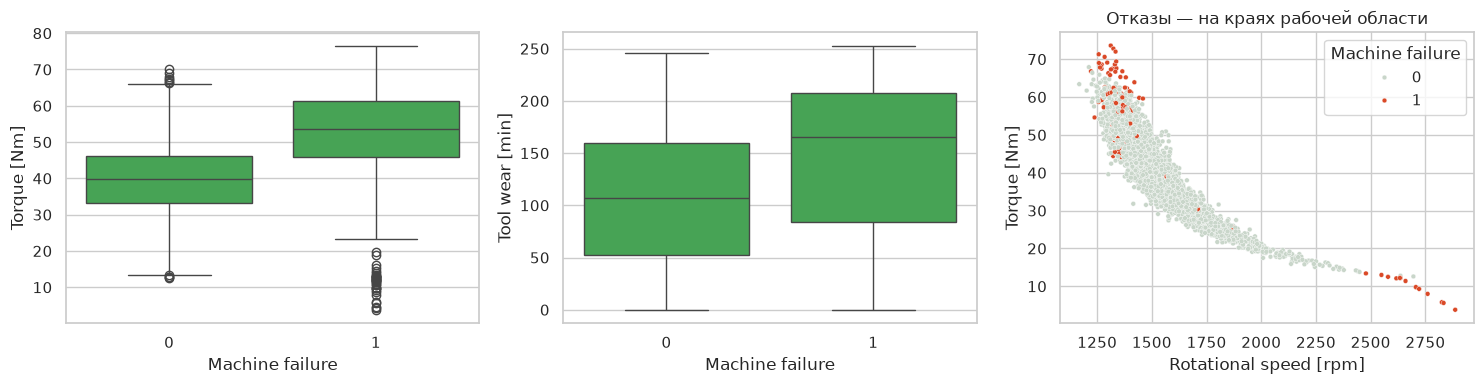

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=df, x="Machine failure", y="Torque [Nm]", ax=ax[0])
sns.boxplot(data=df, x="Machine failure", y="Tool wear [min]", ax=ax[1])
sns.scatterplot(data=df.sample(4000, random_state=1), x="Rotational speed [rpm]", y="Torque [Nm]",
                hue="Machine failure", palette=["#c9d6ca", "#DA4927"], s=12, ax=ax[2])
ax[2].set_title("Отказы — на краях рабочей области")
plt.tight_layout(); plt.show()

**Вывод:** отказы концентрируются при большом моменте, большом износе и на краях области «обороты × момент». Связь **нелинейная** — простая линейная модель на «сырых» датчиках её не увидит. Подскажем модели физику: пороги взяты из описания датасета (аналог паспорта оборудования и регламента ТОиР).

In [7]:
df["power_W"] = df["Torque [Nm]"] * df["Rotational speed [rpm]"] * 2 * np.pi / 60   # мощность = момент × угловая скорость
df["dT_K"] = df["Process temperature [K]"] - df["Air temperature [K]"]                  # запас по теплу
df["strain"] = df["Tool wear [min]"] * df["Torque [Nm]"]                                # нагрузка на изношенный инструмент
df["power_out_of_range"] = ((df["power_W"] < 3500) | (df["power_W"] > 9000)).astype(int)
df["heat_risk"] = ((df["dT_K"] < 8.6) & (df["Rotational speed [rpm]"] < 1380)).astype(int)
X_fe = pd.concat([X_raw, df[["power_W", "dT_K", "strain", "power_out_of_range", "heat_risk"]]], axis=1)
df.groupby("heat_risk")["Machine failure"].mean().round(3)

heat_risk
0    0.023
1    1.000
Name: Machine failure, dtype: float64

## Шаги 7–10. Модели и «парадокс точности»

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             accuracy_score, precision_score, recall_score, f1_score, roc_auc_score)

def quality(y_true, y_pred, y_proba=None, name="модель"):
    """Печатает ключевые метрики качества классификатора одной строкой."""
    line = (f"{name:<28} accuracy={accuracy_score(y_true, y_pred):.3f}  "
            f"precision={precision_score(y_true, y_pred, zero_division=0):.3f}  "
            f"recall={recall_score(y_true, y_pred):.3f}  f1={f1_score(y_true, y_pred):.3f}")
    if y_proba is not None:
        line += f"  ROC-AUC={roc_auc_score(y_true, y_proba):.3f}"
    print(line)

res = {}
for name, X, cw in [("1. сырые датчики", X_raw, None),
                    ("2. + веса классов", X_raw, "balanced"),
                    ("3. + физ. признаки", X_fe, None),
                    ("4. физ. признаки + веса", X_fe, "balanced")]:
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight=cw)).fit(X_tr, y_tr)
    p = m.predict(X_te); res[name] = confusion_matrix(y_te, p)
    quality(y_te, p, m.predict_proba(X_te)[:, 1], name=name)
quality(y_te, np.zeros_like(y_te), name="Базовая линия «отказов нет»")

1. сырые датчики             accuracy=0.968  precision=0.600  recall=0.141  f1=0.229  ROC-AUC=0.877
2. + веса классов            accuracy=0.825  precision=0.139  recall=0.800  f1=0.237  ROC-AUC=0.884
3. + физ. признаки           accuracy=0.990  precision=1.000  recall=0.694  f1=0.819  ROC-AUC=0.981
4. физ. признаки + веса      accuracy=0.926  precision=0.305  recall=0.918  f1=0.457  ROC-AUC=0.983
Базовая линия «отказов нет»  accuracy=0.966  precision=0.000  recall=0.000  f1=0.000


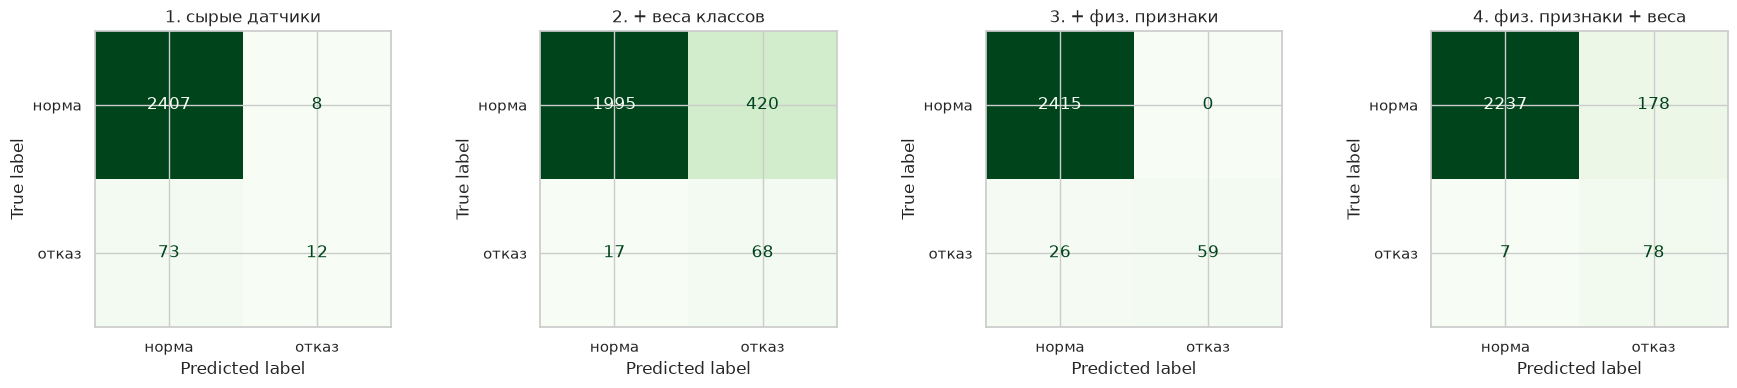

In [9]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, (name, cm) in zip(ax, res.items()):
    ConfusionMatrixDisplay(cm, display_labels=["норма", "отказ"]).plot(ax=a, cmap="Greens", colorbar=False); a.set_title(name)
plt.tight_layout(); plt.show()

## Бонус: кластеризация — типовые режимы работы (обучение без учителя)

In [10]:
from sklearn.cluster import KMeans
Z = StandardScaler().fit_transform(df[["Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]])
df["regime"] = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(Z)
df.groupby("regime").agg(n=("UDI", "size"), rpm=("Rotational speed [rpm]", "mean"), torque=("Torque [Nm]", "mean"),
                         wear=("Tool wear [min]", "mean"), failure_rate=("Machine failure", "mean")).round(3)

,n,rpm,torque,wear,failure_rate
regime,,,,,
0,2761,1574.399,35.651,161.022,0.011
1,2548,1391.651,50.718,141.838,0.093
2,3428,1493.042,41.412,45.278,0.011
3,1263,1881.846,23.949,93.676,0.029


## Итоговые выводы для бизнеса

1. **Парадокс точности:** модель на сырых датчиках даёт 96,8% accuracy (≈ базовая линия 96,6%), но находит лишь **12 из 85** отказов в тесте — для цеха она бесполезна.
2. **Веса классов** поднимают recall до 0,80, но дают 420 ложных тревог из 2500 циклов.
3. **Физические признаки** (мощность, запас по теплу, нагрузка на инструмент) + веса: найдено **78 из 85 отказов (recall 0,92)** при 178 ложных тревогах; ROC-AUC 0,98. Без весов — 59 из 85 и **ни одной ложной тревоги** (precision 1,0).
4. **Управленческий выбор:** вариант 3 — «осмотр только по надёжному сигналу», вариант 4 — «не пропустить отказ». Выбор определяется соотношением стоимости простоя и осмотра — это задача менеджера, а не алгоритма.
5. **Кластеризация** выделяет режимы работы с разной частотой отказов → основа для норм эксплуатации и графика ТОиР.

**Ограничения:** датасет синтетический (построен по реальной логике отказов), для внедрения — данные своего оборудования (MES/SCADA).